## 1. Install/import dependencies

If `pytorch-grad-cam` is not installed in this environment, run the install command once.

In [1]:
# Run this if needed:
%pip install grad-cam

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/47.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/47.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/47.8 MB ? eta -:--:--
   ---------------------------------------- 0.5/47.8 MB 2.7 MB/s eta 0:00:18
    --------------------------------------- 0.8/47.8 MB 1.6 MB/s eta 0:00:29
   - -------------------------------------- 1.6/47.8 MB 2.1 MB/s eta 0:00:23
   - -------------------------------------- 1.8/47.8 MB 2.0 MB/s eta 0:00:23
   - -------------------------------------- 2.4/47.8 MB 2.0 MB/s eta 0:00:24
   -- ------------------------------------- 2.6/47.8 MB 1.9 MB/s eta 0:00:2


[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torchvision import models, transforms

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

## 2. Configure paths, device, and class labels


In [ ]:
WEIGHTS_PATH = Path("./saved_model.pth")
IMAGE_PATH = Path("./dataset/F_Normal/FN_2.jpg")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class_names = [
    "F_Breakage",
    "F_Crushed",
    "F_Normal",
    "R_Breakage",
    "R_Crushed",
    "R_Normal",
]

display_names = {
    "F_Breakage": "Front Breakage",
    "F_Crushed": "Front Crushed",
    "F_Normal": "Front Normal",
    "R_Breakage": "Rear Breakage",
    "R_Crushed": "Rear Crushed",
    "R_Normal": "Rear Normal",
}

Using device: cuda


## 3. Recreate the exact model architecture and load the saved weights


In [ ]:
class CarClassifierResNet(nn.Module):
    def __init__(self, num_classes=6, dropout_rate=0.2):
        super().__init__()

        self.model = models.resnet50(weights=None)

        self.model.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(self.model.fc.in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)


model = CarClassifierResNet(
    num_classes=len(class_names),
    dropout_rate=0.2
)

state_dict = torch.load(
    WEIGHTS_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

print("Trained model loaded successfully.")
print("Output classes:", len(class_names))

Trained model loaded successfully.
Output classes: 6


## 4. Prepare the input image

In [11]:
inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

original_image = Image.open(IMAGE_PATH).convert("RGB")
resized_image = original_image.resize((224, 224))

# Shape: [1, 3, 224, 224]
input_tensor = inference_transform(original_image).unsqueeze(0).to(device)

# RGB image in [0, 1], used later to overlay the heatmap.
rgb_image = np.asarray(resized_image).astype(np.float32) / 255.0

print("Input tensor shape:", tuple(input_tensor.shape))

Input tensor shape: (1, 3, 224, 224)


## 5. Get the model prediction

This is an ordinary inference pass. `torch.no_grad()` is appropriate here because we only need the predicted class and probabilities.

In [12]:
with torch.no_grad():
    logits = model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_index = int(torch.argmax(probabilities).item())
predicted_folder = class_names[predicted_index]
predicted_label = display_names[predicted_folder]
confidence = float(probabilities[predicted_index].item())

print(f"Prediction: {predicted_label}")
print(f"Confidence: {confidence:.2%}")

print("\nClass probabilities:")
for index, folder_name in enumerate(class_names):
    print(f"{display_names[folder_name]:16s}: {probabilities[index].item():.2%}")

Prediction: Front Normal
Confidence: 100.00%

Class probabilities:
Front Breakage  : 0.00%
Front Crushed   : 0.00%
Front Normal    : 100.00%
Rear Breakage   : 0.00%
Rear Crushed    : 0.00%
Rear Normal     : 0.00%


## 6. Generate Grad-CAM for the predicted class

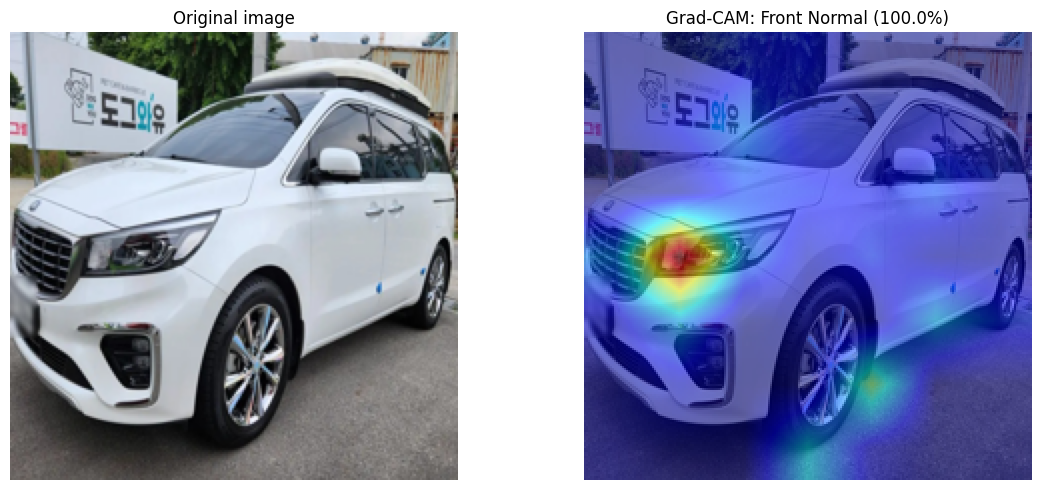

In [13]:
target_layers = [model.model.layer4[-1]]
predicted_target = [ClassifierOutputTarget(predicted_index)]

# Keep gradient calculation enabled for Grad-CAM.
input_tensor_for_cam = input_tensor.clone().detach().requires_grad_(True)

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

predicted_cam = cam(
    input_tensor=input_tensor_for_cam,
    targets=predicted_target
)[0]

predicted_overlay = show_cam_on_image(
    rgb_image,
    predicted_cam,
    use_rgb=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(predicted_overlay)
axes[1].set_title(f"Grad-CAM: {predicted_label} ({confidence:.1%})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 7. Optional: Generate a heatmap for each of the six classes


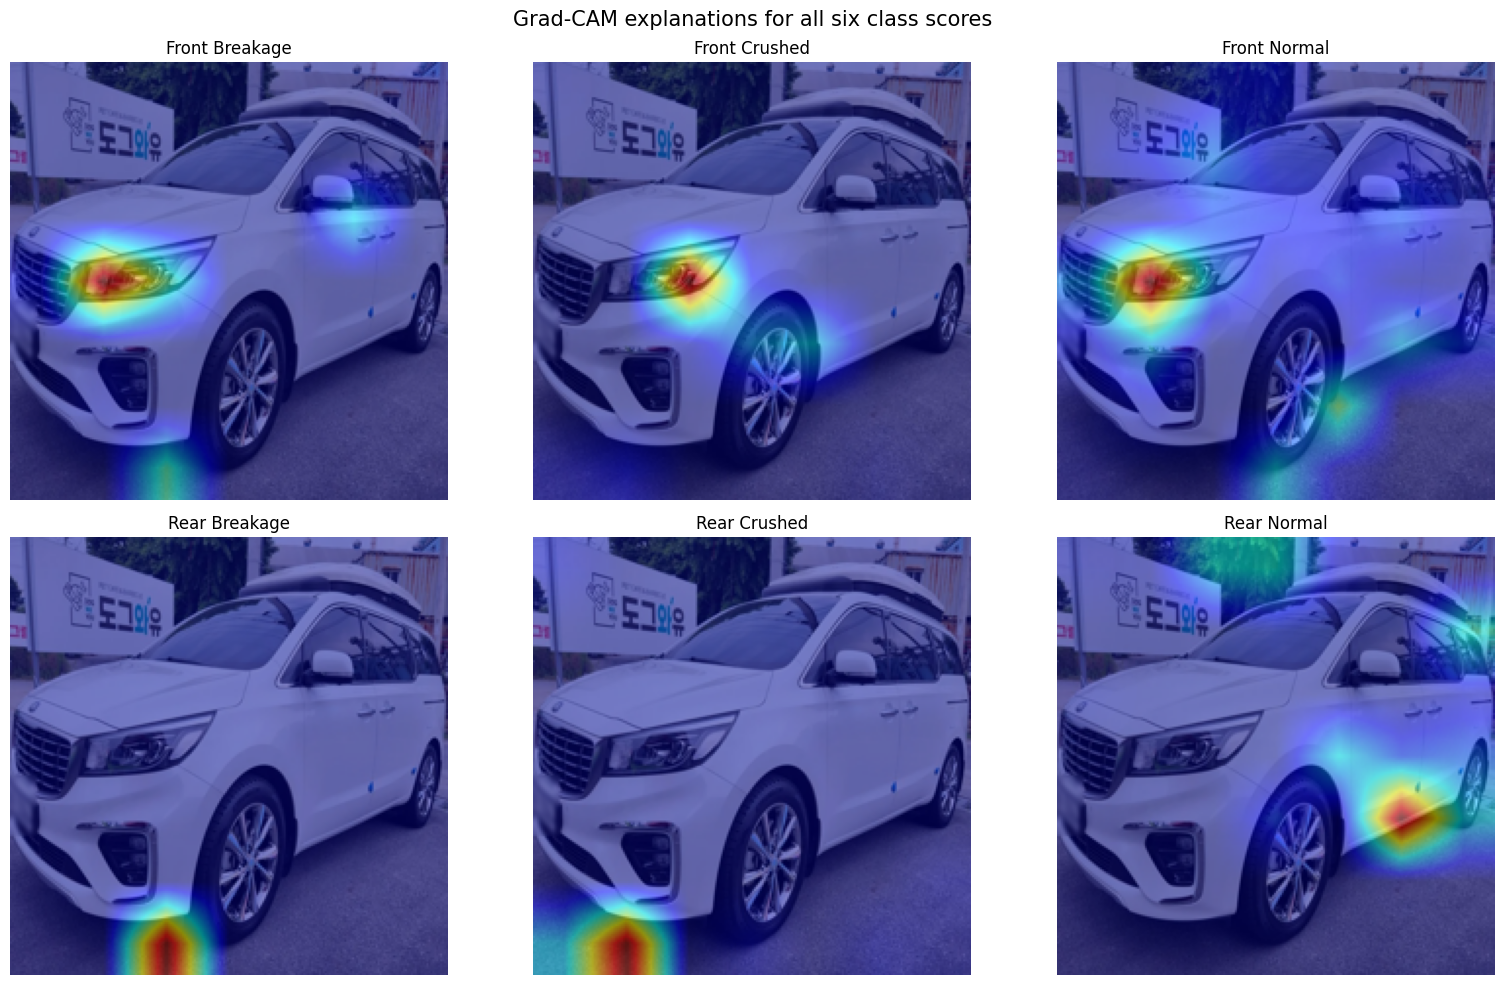

In [14]:
all_class_cams = []

for class_index in range(len(class_names)):
    target = [ClassifierOutputTarget(class_index)]

    class_cam = cam(
        input_tensor=input_tensor_for_cam,
        targets=target
    )[0]

    all_class_cams.append(class_cam)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for class_index, ax in enumerate(axes.flat):
    overlay = show_cam_on_image(
        rgb_image,
        all_class_cams[class_index],
        use_rgb=True
    )

    ax.imshow(overlay)
    ax.set_title(display_names[class_names[class_index]])
    ax.axis("off")

plt.suptitle("Grad-CAM explanations for all six class scores", fontsize=15)
plt.tight_layout()
plt.show()

## 9. How to interpret the result

- A heatmap that concentrates around visibly damaged front/rear bodywork is consistent with the intended classification evidence.
- If it highlights the background, road, watermark, or unrelated parts of the image, investigate possible dataset bias.
- If two similar classes highlight similar regions, inspect examples from those classes and the model's confusion matrix.
- Grad-CAM is not proof that the model understands damage, and it does not locate exact damaged pixels. It is a diagnostic visualization.
